# IMDB Sentiment Analysis: Data Discovery & Preparation

**Project:** Sentiment Analysis with LSTM (from scratch) vs. Pretrained BERT  
**Stack:** PyTorch, HuggingFace `datasets` & `transformers`

### Objectives
1. **Load & Inspect** the local IMDB dataset (`data/imdb_raw`).
2. **Exploratory Data Analysis (EDA):**
   - Split sizes, features, and label mapping (`neg` / `pos`).
   - Missing values, empty reviews, exact duplicates, and train/test overlap.
   - Class balance and review length distributions (characters, words, HTML artifacts).
3. **Prepare Data for Both Models:**
   - Clean HTML tags/entities and normalize whitespace.
   - Deduplicate `train` and create a stratified **90/10 train/validation split**, keeping `test` untouched.
   - Build and evaluate an **LSTM vocabulary** (fit strictly on `train`) + sequence length budget.
   - Verify **BERT (`bert-base-uncased`)** subword tokenization & truncation rates.
   - Save the prepared `DatasetDict` and `lstm_vocab.json` to `data/imdb_prepared`.


In [1]:
import html
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import ClassLabel, Dataset, DatasetDict, load_from_disk
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("data/imdb_raw")
OUT_DIR = Path("data/imdb_prepared")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

c:\project\sentiment-lstm-vs-bert\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Raw Dataset & Basic Inspection


In [2]:
raw_ds = load_from_disk(str(DATA_DIR))
print(raw_ds)
print("\nTrain features:", raw_ds["train"].features)
label_names = raw_ds["train"].features["label"].names
print("Label mapping:", {i: name for i, name in enumerate(label_names)})

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Train features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}
Label mapping: {0: 'neg', 1: 'pos'}


In [3]:
train_df = raw_ds["train"].to_pandas()
test_df = raw_ds["test"].to_pandas()

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

print("\nMissing values (train):", train_df.isna().sum().to_dict())
print("Missing values (test): ", test_df.isna().sum().to_dict())

empty_train = (train_df["text"].str.strip() == "").sum()
empty_test = (test_df["text"].str.strip() == "").sum()
print(f"Empty reviews -> train: {empty_train}, test: {empty_test}")

train_dups = train_df["text"].duplicated().sum()
test_dups = test_df["text"].duplicated().sum()
overlap = len(set(train_df["text"]).intersection(set(test_df["text"])))
print(f"Exact duplicates -> within train: {train_dups}, within test: {test_dups}, train-test overlap: {overlap}")

Train shape: (25000, 2)
Test shape:  (25000, 2)

Missing values (train): {'text': 0, 'label': 0}
Missing values (test):  {'text': 0, 'label': 0}
Empty reviews -> train: 0, test: 0
Exact duplicates -> within train: 96, within test: 199, train-test overlap: 123


In [4]:
# Inspect sample positive and negative reviews
for label_id, label_name in enumerate(label_names):
    sample = train_df[train_df["label"] == label_id]["text"].iloc[0]
    print(f"--- Sample [{label_name.upper()} ({label_id})] ---")
    print(sample[:400].replace("\n", " "), "...\n")

--- Sample [NEG (0)] ---
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student name ...

--- Sample [POS (1)] ---
Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more striking in contrast with the natives.<br /><br />But I'd have to say that The Third Man has a more well- ...



## 2. Exploratory Data Analysis (EDA)


In [5]:
def add_text_stats(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["sentiment"] = out["label"].map({0: "neg", 1: "pos"})
    out["char_len"] = out["text"].str.len()
    out["word_count"] = out["text"].str.split().str.len()
    out["br_count"] = out["text"].str.count(r"<br\s*/?>", flags=re.IGNORECASE)
    return out

train_stats = add_text_stats(train_df)
test_stats = add_text_stats(test_df)

print("Class balance (train):")
print(train_stats["sentiment"].value_counts())
print("\nClass balance (test):")
print(test_stats["sentiment"].value_counts())

print(f"\nReviews containing <br> tags -> train: {(train_stats['br_count'] > 0).mean():.1%}, test: {(test_stats['br_count'] > 0).mean():.1%}")
print("\nTrain word count percentiles:")
print(train_stats["word_count"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(1))
print("\nTest word count percentiles:")
print(test_stats["word_count"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(1))

Class balance (train):
sentiment
neg    12500
pos    12500
Name: count, dtype: int64

Class balance (test):
sentiment
neg    12500
pos    12500
Name: count, dtype: int64

Reviews containing <br> tags -> train: 58.7%, test: 58.1%

Train word count percentiles:
count    25000.0
mean       233.8
std        173.7
min         10.0
50%        174.0
75%        284.0
90%        458.0
95%        598.0
99%        913.0
max       2470.0
Name: word_count, dtype: float64

Test word count percentiles:
count    25000.0
mean       228.5
std        168.9
min          4.0
50%        172.0
75%        277.0
90%        444.0
95%        582.0
99%        901.0
max       2278.0
Name: word_count, dtype: float64


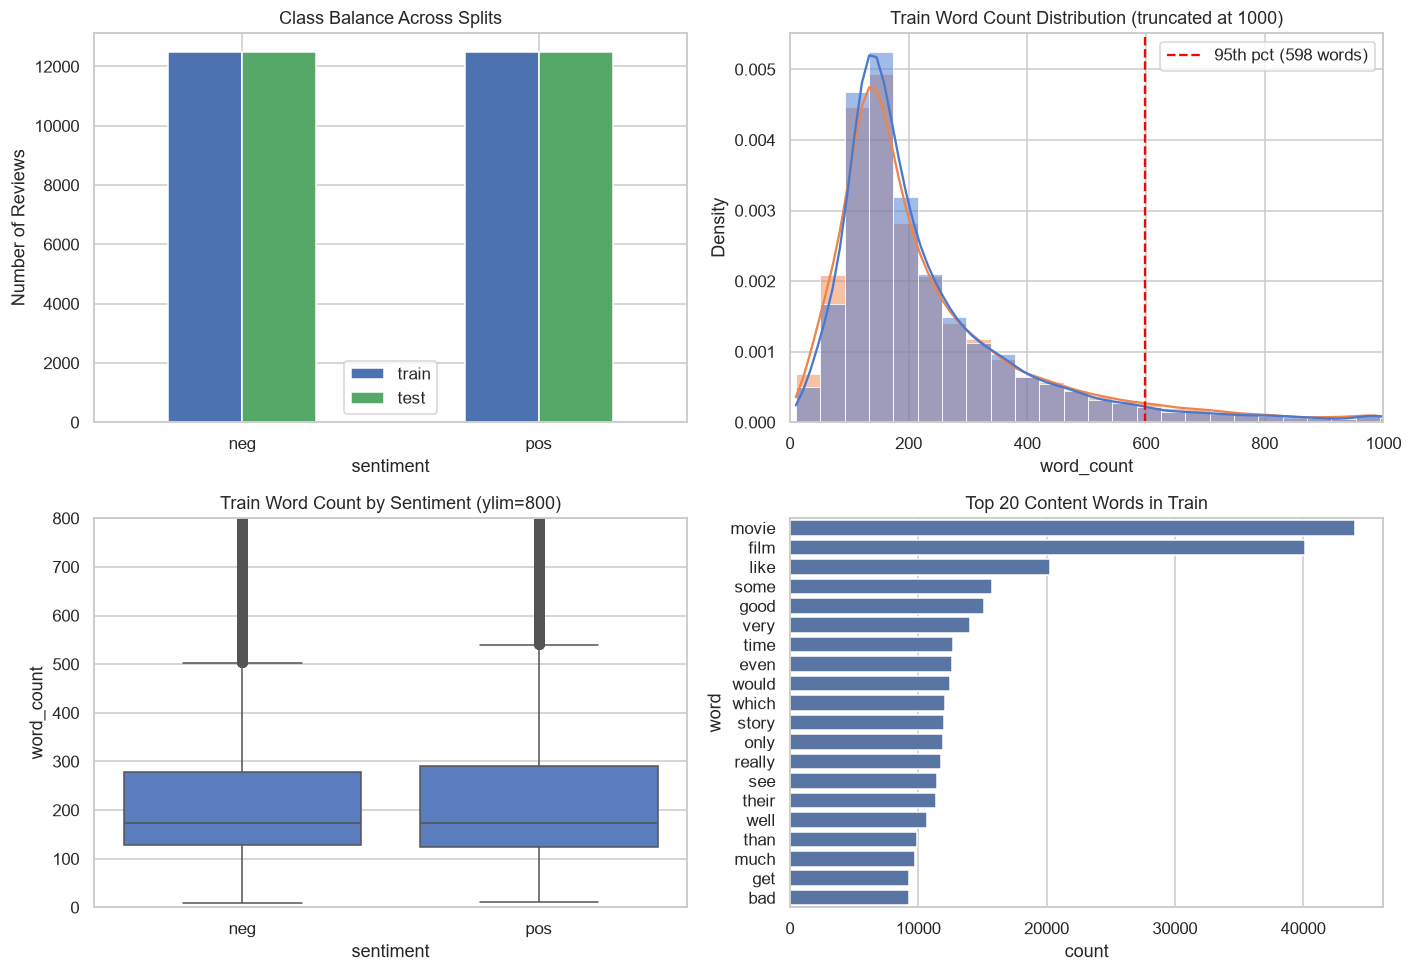

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Class distribution
split_counts = pd.DataFrame({
    "train": train_stats["sentiment"].value_counts(),
    "test": test_stats["sentiment"].value_counts(),
})
split_counts.plot(kind="bar", ax=axes[0, 0], rot=0, color=["#4C72B0", "#55A868"])
axes[0, 0].set_title("Class Balance Across Splits")
axes[0, 0].set_ylabel("Number of Reviews")

# 2. Word count distribution by sentiment (train)
p95 = train_stats["word_count"].quantile(0.95)
sns.histplot(
    data=train_stats, x="word_count", hue="sentiment",
    bins=60, kde=True, stat="density", common_norm=False, ax=axes[0, 1]
)
axes[0, 1].axvline(p95, color="red", linestyle="--", label=f"95th pct ({p95:.0f} words)")   
axes[0, 1].set_xlim(0, 1000)
axes[0, 1].set_title("Train Word Count Distribution (truncated at 1000)")
axes[0, 1].legend()

# 3. Word count boxplot by sentiment
sns.boxplot(data=train_stats, x="sentiment", y="word_count", ax=axes[1, 0])
axes[1, 0].set_ylim(0, 800)
axes[1, 0].set_title("Train Word Count by Sentiment (ylim=800)")

# 4. Top 20 raw tokens (excluding common English stopwords & HTML br)
basic_stopwords = {
    "the", "a", "an", "and", "or", "but", "in", "on", "at", "to", "for", "of",
    "with", "by", "is", "it", "this", "that", "was", "are", "be", "as", "i",
    "you", "he", "she", "they", "we", "his", "her", "my", "not", "have", "has",
    "had", "from", "one", "all", "so", "if", "out", "about", "who", "what",
    "there", "were", "when", "can", "will", "just", "more", "up", "no", "br",
}
token_counter = Counter()
for text in train_stats["text"]:
    tokens = re.findall(r"[a-z]+", text.lower())
    token_counter.update(t for t in tokens if t not in basic_stopwords and len(t) > 2)

top_words = pd.DataFrame(token_counter.most_common(20), columns=["word", "count"])
sns.barplot(data=top_words, y="word", x="count", ax=axes[1, 1], color="#4C72B0")
axes[1, 1].set_title("Top 20 Content Words in Train")

plt.tight_layout()
plt.show()

## 3. Data Cleaning & Train/Validation Split

- **Cleaning:** Unescape HTML entities, replace `<br />` and any remaining HTML tags with spaces, and collapse extra whitespace. We keep punctuation and original casing so **BERT** gets natural text while the **LSTM** tokenizer handles lowercasing.
- **Deduplication & Split:** Drop exact duplicate texts from `train` so identical reviews cannot leak between `train` and `validation`. Then perform a **90/10 stratified split** (`SEED = 42`), leaving `test` completely untouched.


In [7]:
HTML_TAG_RE = re.compile(r"<[^>]+>")
WHITESPACE_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = HTML_TAG_RE.sub(" ", text)
    text = WHITESPACE_RE.sub(" ", text).strip()
    return text

train_df["text"] = train_df["text"].map(clean_text)
test_df["text"] = test_df["text"].map(clean_text)

before_dedup = len(train_df)
train_df = train_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
print(f"Removed {before_dedup - len(train_df)} duplicate rows from train ({len(train_df)} remaining).")

train_split_df, val_split_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df["label"],
)
train_split_df = train_split_df.reset_index(drop=True)
val_split_df = val_split_df.reset_index(drop=True)

print(f"Final split sizes -> train: {len(train_split_df)}, validation: {len(val_split_df)}, test: {len(test_df)}")
print("Train label ratio:", train_split_df["label"].value_counts(normalize=True).round(4).to_dict())
print("Val label ratio:  ", val_split_df["label"].value_counts(normalize=True).round(4).to_dict())

Removed 98 duplicate rows from train (24902 remaining).
Final split sizes -> train: 22411, validation: 2491, test: 25000
Train label ratio: {1: 0.5008, 0: 0.4992}
Val label ratio:   {1: 0.501, 0: 0.499}


## 4. LSTM Preparation: Tokenizer, Vocabulary & Sequence Length


In [8]:
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
MAX_VOCAB_SIZE = 25_000
MIN_FREQ = 2

def lstm_tokenize(text: str) -> list[str]:
    return re.findall(r"[a-z0-9']+", text.lower())

# Fit vocabulary strictly on train_split_df
vocab_counter = Counter()
train_lengths = []
for text in train_split_df["text"]:
    toks = lstm_tokenize(text)
    vocab_counter.update(toks)
    train_lengths.append(len(toks))

most_common = [
    word for word, freq in vocab_counter.most_common(MAX_VOCAB_SIZE - 2)
    if freq >= MIN_FREQ
]
token_to_idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for word in most_common:
    token_to_idx[word] = len(token_to_idx)

def compute_coverage(texts: pd.Series, vocab: dict[str, int]) -> float:
    total = 0
    covered = 0
    for t in texts:
        toks = lstm_tokenize(t)
        total += len(toks)
        covered += sum(1 for tok in toks if tok in vocab)
    return covered / total if total else 0.0

train_cov = compute_coverage(train_split_df["text"], token_to_idx)
val_cov = compute_coverage(val_split_df["text"], token_to_idx)

p90_len, p95_len = np.percentile(train_lengths, [90, 95])
print(f"Total unique tokens in train: {len(vocab_counter):,}")
print(f"LSTM vocab size (min_freq={MIN_FREQ}, cap={MAX_VOCAB_SIZE:,}): {len(token_to_idx):,}")
print(f"Token coverage -> train: {train_cov:.2%}, validation: {val_cov:.2%}")
print(f"Cleaned LSTM token length -> 90th pct: {p90_len:.0f}, 95th pct: {p95_len:.0f}")

Total unique tokens in train: 83,197
LSTM vocab size (min_freq=2, cap=25,000): 25,000
Token coverage -> train: 97.91%, validation: 97.54%
Cleaned LSTM token length -> 90th pct: 459, 95th pct: 602


## 5. BERT Preparation Check (`bert-base-uncased`)


In [9]:
from transformers import AutoTokenizer

BERT_MODEL_NAME = "bert-base-uncased"
try:
    bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    sample_texts = train_split_df["text"].sample(n=2000, random_state=SEED).tolist()
    enc = bert_tokenizer(sample_texts, truncation=False, padding=False)
    bert_lengths = np.array([len(ids) for ids in enc["input_ids"]])

    print(f"BERT tokenizer '{BERT_MODEL_NAME}' loaded (vocab_size={bert_tokenizer.vocab_size:,}).")
    print(
        f"Subword lengths (n=2000) -> mean: {bert_lengths.mean():.1f}, "
        f"90th: {np.percentile(bert_lengths, 90):.0f}, "
        f"95th: {np.percentile(bert_lengths, 95):.0f}, "
        f"max: {bert_lengths.max()}"
    )
    print(f"Truncated at 256 tokens: {(bert_lengths > 256).mean():.1%}")
    print(f"Truncated at 512 tokens: {(bert_lengths > 512).mean():.1%}")
except Exception as exc:
    print(f"Could not load '{BERT_MODEL_NAME}' tokenizer (offline or hub unavailable): {exc}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (660 > 512). Running this sequence through the model will result in indexing errors


BERT tokenizer 'bert-base-uncased' loaded (vocab_size=30,522).
Subword lengths (n=2000) -> mean: 302.2, 90th: 605, 95th: 770, max: 2166
Truncated at 256 tokens: 42.4%
Truncated at 512 tokens: 13.9%


## 6. Save Prepared Dataset & LSTM Vocabulary


In [10]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

features = raw_ds["train"].features
prepared_ds = DatasetDict({
    "train": Dataset.from_pandas(train_split_df[["text", "label"]], features=features, preserve_index=False),
    "validation": Dataset.from_pandas(val_split_df[["text", "label"]], features=features, preserve_index=False),
    "test": Dataset.from_pandas(test_df[["text", "label"]], features=features, preserve_index=False),
})
prepared_ds.save_to_disk(str(OUT_DIR))

lstm_vocab_payload = {
    "pad_token": PAD_TOKEN,
    "unk_token": UNK_TOKEN,
    "pad_id": token_to_idx[PAD_TOKEN],
    "unk_id": token_to_idx[UNK_TOKEN],
    "max_vocab_size": MAX_VOCAB_SIZE,
    "min_freq": MIN_FREQ,
    "recommended_max_len": 256,
    "token_to_idx": token_to_idx,
}
vocab_path = OUT_DIR / "lstm_vocab.json"
vocab_path.write_text(json.dumps(lstm_vocab_payload, indent=2), encoding="utf-8")

print("Saved prepared dataset to:", OUT_DIR.resolve())
print("Saved LSTM vocabulary to: ", vocab_path.resolve())
print(prepared_ds)

Saving the dataset (1/1 shards): 100%|██████████| 25000/25000 [00:00<00:00, 513924.71 examples/s]

Saved prepared dataset to: C:\project\sentiment-lstm-vs-bert\data\imdb_prepared
Saved LSTM vocabulary to:  C:\project\sentiment-lstm-vs-bert\data\imdb_prepared\lstm_vocab.json
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 22411
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2491
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
})
